# Modèles de référence

Ce notebook pose les premières mesures : une référence naïve et une régression logistique, évaluées par validation croisée sur l'entraînement.

Règles suivies, décidées avant de regarder le moindre résultat :

- **Le jeu de test n'est pas utilisé ici.** Il est réservé à l'évaluation finale, une seule fois, pour mesurer et non pour choisir.
- **La validation croisée est stratifiée** (5 plis) : chaque pli garde les mêmes proportions de familles que l'ensemble.
- **Le prétraitement est ajusté dans chaque pli séparément**, grâce au `Pipeline` : aucune information d'un pli de validation ne sert à l'apprentissage.
- **L'accuracy ne suffit pas.** On suit surtout le **rappel** (quelle part des attaques est détectée) et la **précision** (quelle part des alertes est justifiée). Rater une attaque coûte plus cher qu'une fausse alerte.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from intrusion_detector.data import CATEGORIES, load_train, split_features_target
from intrusion_detector.evaluate import (
    cross_val_predictions,
    cross_validate_binary,
    per_class_report,
    plot_confusion_matrix,
)
from intrusion_detector.models import baseline_models
from intrusion_detector.preprocessing import build_preprocessor

sns.set_theme(style="whitegrid", context="notebook")

In [2]:
train = load_train()
X, y_binary = split_features_target(train, target="is_attack")
_, y_family = split_features_target(train, target="category")
models = baseline_models()

n_columns = build_preprocessor().fit_transform(X).shape[1]
print(f"{X.shape[1]} variables en entrée, {n_columns} colonnes après prétraitement")
print("Modèles comparés :", list(models))

41 variables en entrée, 121 colonnes après prétraitement
Modèles comparés : ['Référence (classe majoritaire)', 'Régression logistique']


## 1. Détection binaire : normal ou attaque

Les métriques, pour la classe « attaque » :

- **précision** : parmi les connexions signalées, la part qui sont vraiment des attaques ;
- **rappel** : parmi les vraies attaques, la part qui est détectée ;
- **F1** : la moyenne harmonique des deux ;
- **ROC AUC** : la capacité du modèle à classer les attaques au-dessus des connexions normales, quel que soit le seuil de décision.

In [3]:
binary_tables = {name: cross_validate_binary(model, X, y_binary) for name, model in models.items()}

pd.DataFrame({name: table["moyenne"] for name, table in binary_tables.items()}).T.round(4)

,accuracy,precision,recall,f1,roc_auc
Référence (classe majoritaire),0.5346,0.0000,0.0000,0.0000,0.5000
Régression logistique,0.9728,0.9775,0.9638,0.9706,0.9964


In [4]:
binary_tables["Régression logistique"].round(4)

,moyenne,écart-type
accuracy,0.9728,0.0016
precision,0.9775,0.0016
recall,0.9638,0.0026
f1,0.9706,0.0017
roc_auc,0.9964,0.0003


La référence naïve montre pourquoi l'accuracy trompe : en répondant toujours « normal », elle obtient 53,5 % d'accuracy sans détecter la moindre attaque (rappel de 0). La régression logistique détecte 96,4 % des attaques, avec 97,8 % d'alertes justifiées et un ROC AUC de 0,996. L'écart-type entre les plis est inférieur à 0,3 point : le résultat est stable.

Ces scores sont toutefois optimistes. Chaque pli de validation contient les mêmes types d'attaques que ceux sur lesquels le modèle s'entraîne, alors que le jeu de test en contient 17 qu'il n'a jamais vus. L'écart entre ces chiffres et le score final sera l'un des résultats les plus instructifs du projet.

## 2. Cinq familles : normal, DoS, Probe, R2L, U2R

Ici, chaque connexion est prédite par un modèle qui ne l'a jamais vue (validation croisée « hors pli »), puis on regarde les résultats famille par famille. La moyenne non pondérée (macro) donne le même poids à U2R, qui compte 52 exemples, qu'au trafic normal, qui en compte plus de 67 000.

In [5]:
family_predictions = {
    name: cross_val_predictions(model, X, y_family) for name, model in models.items()
}

reference_macro = per_class_report(*family_predictions["Référence (classe majoritaire)"]).loc["macro avg", ["precision", "recall", "f1"]]
print("Référence naïve, moyenne macro :")
print(reference_macro.round(3).to_string())

Référence naïve, moyenne macro :
precision    0.107
recall       0.200
f1           0.139


In [6]:
logistic_report = per_class_report(*family_predictions["Régression logistique"])
logistic_report.round(3)

,precision,recall,f1,support
normal,0.988,0.991,0.990,67343
dos,0.996,0.998,0.997,45927
probe,0.976,0.960,0.968,11656
r2l,0.794,0.781,0.787,995
u2r,0.645,0.385,0.482,52
macro avg,0.880,0.823,0.845,125973


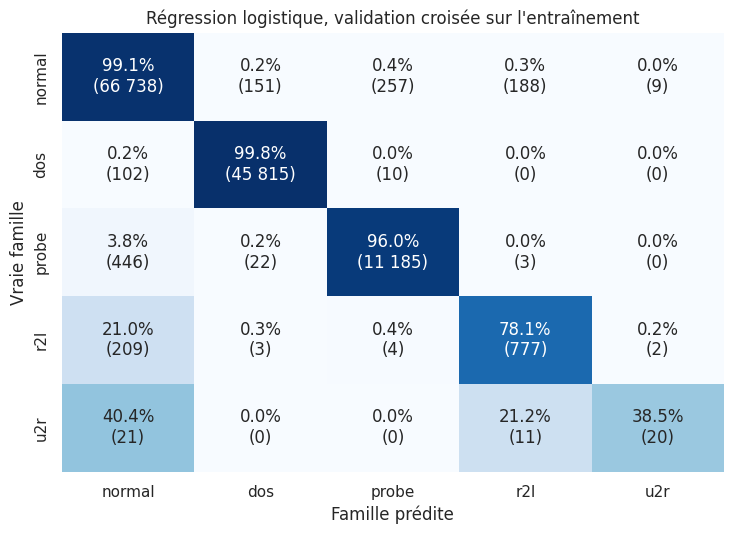

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
plot_confusion_matrix(
    *family_predictions["Régression logistique"],
    title="Régression logistique, validation croisée sur l'entraînement",
    ax=ax,
)
fig.tight_layout()
plt.show()

Les trois grandes familles sont bien reconnues : normal, DoS et Probe dépassent 96 % de rappel. Les deux familles rares, elles, ne le sont pas.

- **R2L** : rappel de 78,1 %. Un cas sur cinq (209 sur 995) est pris pour du trafic normal.
- **U2R** : rappel de 38,5 %. Sur 52 connexions, 21 sont prises pour du trafic normal et 11 pour du R2L.

La matrice de confusion confirme ce que l'exploration laissait prévoir : les erreurs sur ces deux familles vont surtout vers « normal », parce que ces attaques ressemblent à des sessions légitimes. U2R et R2L se confondent aussi entre elles, ce qui correspond à leurs profils proches sur les variables observées.

La moyenne macro (précision 0,880, rappel 0,823, F1 0,845) donne le même poids à chaque famille. C'est le chiffre à suivre, car il ne se laisse pas gonfler par les 67 000 connexions normales. La référence naïve n'obtient que 0,139 de F1 macro.

## 3. Ce qu'on en retient

- Le prétraitement fonctionne, et le `Pipeline` évite toute fuite d'information entre les plis.
- La régression logistique est une bonne référence : 96,4 % de rappel en binaire, F1 macro de 0,845 sur cinq familles.
- Le point faible est identifié : R2L, et surtout U2R (rappel de 38,5 %). C'est là que les modèles suivants devront apporter quelque chose.
- Ces chiffres viennent de la validation croisée sur l'entraînement. Ils ne disent encore rien de la capacité à détecter des attaques nouvelles : c'est le rôle du jeu de test, utilisé une seule fois à la fin.

Prochaine étape : comparer des modèles plus puissants (forêt aléatoire, gradient boosting) avec exactement la même méthode.